# Supplementary figure: the Cristiano and Jiang cohorts compared

Figure S12 (panels a-c, code copied from `figS12.ipynb`), optionally with panel d (panel m of the
assembled Figure S10 in `figS10.ipynb`):
- a: fragment-length distributions per cohort and clinical group;
- b: per-sample technical measures by cohort and group (coverage, fragment count, mean fragment
  length, short/long ratio, mean fragment GC, sex inferred from the reads, ichorCNA tumor fraction);
- c: AUROC of each measure alone within each cohort (participant bootstrap 95% CI; higher value =
  cancer), next to the TSS model trained within that cohort (fully nested CV, pooled out-of-fold scores);
- d: AUROC of the TSS model in samples with shorter and longer fragments than the median of the
  cohort's healthy donors.

Source data: panels a-c read `data/no_deep/figS12_cohort_scalars.csv`, `figS12_fraglen_distributions.csv`
(from `export/export_figS12_cohorts.py`), `fig3_predictions.csv`, `fig4a_predictions.csv` and
`data/fig4gi_jiang_nested_oof.csv`. Panel d reads `output/no_deep/figS10m_fragment_length_halves.csv`,
written by `figS10.ipynb` (run that notebook first). Fragment-length statistics use the 100-220 bp window.

Output: `output/no_deep/figS_cohort_comparison.png` (600 dpi, shared figure style `_figstyle.py`) and
`.pdf`, and the version with panel d, `figS_cohort_comparison_with_d.*`.

In [1]:
import os
import time

# Data paths are relative to src/figures/; change there if the kernel started elsewhere.
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# Cohort: "no_deep" (default; data/no_deep/, output/no_deep/) or "all", via FIG_COHORT.
COHORT = os.environ.get("FIG_COHORT", "no_deep")
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing - run export/export_figS12_cohorts.py with COHORT_VARIANT={COHORT}"
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


def savefig(fig, name, **kw):
    """fig.savefig with retries (the figures folder can be on a network drive)."""
    for attempt in range(4):
        try:
            fig.savefig(out_path(name), **kw)
            return
        except OSError:
            if attempt == 3:
                raise
            time.sleep(2 * (attempt + 1))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import _figstyle as fs
fs.apply()
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

sc = pd.read_csv(data_path("figS12_cohort_scalars.csv"))
dens = pd.read_csv(data_path("figS12_fraglen_distributions.csv"))
# panel d: the table behind panel m of Fig S10 (written by figS10.ipynb)
FL_HALVES_FILE = out_path("figS10m_fragment_length_halves.csv")
assert os.path.exists(FL_HALVES_FILE), f"{FL_HALVES_FILE} missing - run figS10.ipynb first"
fl_halves = pd.read_csv(FL_HALVES_FILE)
print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

LENGTHS = np.arange(100, 221)
# (cohort, group) keys are the values in the source data; *_NAMES / *_LABELS are what is drawn
GROUP_ORDER = [("Cristiano", "Healthy"), ("Cristiano", "BRCA+CRC"), ("Cristiano", "Other cancer"),
               ("Jiang", "Healthy"), ("Jiang", "Chronic hepatitis B"), ("Jiang", "HBV cirrhosis"), ("Jiang", "HCC")]
GROUP_COLORS = {("Cristiano", "Healthy"): "#2E8B57", ("Cristiano", "BRCA+CRC"): "#0173B2",
                ("Cristiano", "Other cancer"): "#7FB3D5",
                ("Jiang", "Healthy"): "#2E8B57", ("Jiang", "Chronic hepatitis B"): "#E69F00",
                ("Jiang", "HBV cirrhosis"): "#B15928", ("Jiang", "HCC"): "#CA3542"}
GROUP_NAMES = {"Healthy": "healthy", "BRCA+CRC": "BRCA/CRC", "Other cancer": "other cancer",
               "Chronic hepatitis B": "chronic hepatitis B", "HBV cirrhosis": "HBV cirrhosis", "HCC": "HCC"}
GROUP_LABELS = {"Healthy": "H", "BRCA+CRC": "B/C", "Other cancer": "Oth",
                "Chronic hepatitis B": "CHB", "HBV cirrhosis": "Cirr", "HCC": "HCC"}
GROUP_KEY = ("H = healthy, B/C = BRCA/CRC, Oth = other cancer types (Cristiano); "
             "H = healthy, CHB = chronic hepatitis B, Cirr = HBV cirrhosis, HCC = hepatocellular carcinoma (Jiang)")
sc["total_fragments_m"] = sc["total_fragments"] / 1e6
# continuous measures of both cohorts (boxplots in b, AUROCs in c): column, panel title (b), log scale
SCALARS = [("mean_coverage", "Mean coverage\n(x)", False),
           ("total_fragments_m", "Fragments per sample\n(millions)", False),
           ("fragment_length_mean", "Mean fragment length\n(bp)", False),
           ("short_long_ratio", "Short/long ratio\n(100–150 / 151–220 bp)", False),
           ("mean_gc", "Mean fragment GC\n(%)", False)]
# tick labels of panel c
COV_LABELS = {"mean_coverage": "Mean coverage", "total_fragments_m": "Fragments per sample",
              "fragment_length_mean": "Mean fragment length", "short_long_ratio": "Short/long ratio",
              "mean_gc": "Mean fragment GC", "sex_female_bam": "Female",
              "ichorcna_tf": "ichorCNA tumor fraction"}
UNI_COVS = [c for c, _, _ in SCALARS] + ["sex_female_bam", "ichorcna_tf"]

print(sc.groupby(["cohort", "group"]).size().to_string())

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)
cohort     group              
Cristiano  BRCA+CRC                80
           Healthy                164
           Other cancer           123
Jiang      Chronic hepatitis B     67
           HBV cirrhosis           36
           HCC                     90
           Healthy                 32


## Panel a: fragment-length distributions

In [2]:
# shared figure style (_figstyle): drawn at the printed size, 7 pt text, one legend per cohort below the panel
def panel_a(ax):
    cols = [str(l) for l in LENGTHS]
    handles = {"Cristiano": [], "Jiang": []}
    for cohort, group in GROUP_ORDER:
        d = dens[(dens["cohort"] == cohort) & (dens["group"] == group)]
        if d.empty:
            continue
        mean = d[cols].mean(axis=0).to_numpy() * 100
        ln, = ax.plot(LENGTHS, mean, color=GROUP_COLORS[(cohort, group)],
                      linestyle="-" if cohort == "Cristiano" else (0, (3, 1.5)),
                      linewidth=0.8 if group == "Other cancer" else 1.1,
                      label=f"{GROUP_NAMES[group][0].upper() + GROUP_NAMES[group][1:]} (n = {len(d)})")
        handles[cohort].append(ln)
    ax.set_xlabel("Fragment length (bp)")
    ax.set_ylabel("Fragments (%)")
    ax.set_xlim(100, 220)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.arange(100, 221, 20))
    fs.value_grid(ax)
    leg1 = ax.legend(handles=handles["Cristiano"], title="Cristiano et al. (solid)", loc="upper left", bbox_to_anchor=(-0.17, -0.2),
                     alignment="left", handlelength=1.8, borderaxespad=0)
    ax.add_artist(leg1)
    ax.legend(handles=handles["Jiang"], title="Jiang et al. (dashed)", loc="upper left", bbox_to_anchor=(0.42, -0.2),
              alignment="left", handlelength=1.8, borderaxespad=0)

## Panel b: technical measures by cohort and group

In [3]:
# Left of the divider: Cristiano et al.; right: Jiang et al. (key next to the panels)
B_TITLES = {"mean_coverage": "Mean coverage\n(x)", "total_fragments_m": "Fragments per\nsample (millions)",
            "fragment_length_mean": "Mean fragment\nlength (bp)", "short_long_ratio": "Short/long ratio\n(100–150/151–220 bp)",
            "mean_gc": "Mean fragment\nGC (%)", "sex_female_bam": "Female (%),\nsex from the reads", "ichorcna_tf": "ichorCNA tumor\nfraction (log scale)"}


def _cohort_divider(ax, x=2.5):
    ax.axvline(x, color="0.35", linewidth=0.6)


def _boxes(ax, col, groups):
    data = [sc.loc[(sc["cohort"] == c) & (sc["group"] == g), col].dropna().to_numpy() for c, g in groups]
    colors = [GROUP_COLORS[k] for k in groups]
    pos = np.arange(len(data))
    bp = ax.boxplot([d if len(d) else [np.nan] for d in data], positions=pos, widths=0.62,
                    patch_artist=True, showfliers=False, medianprops={"color": "black", "linewidth": 0.9},
                    boxprops={"linewidth": 0.5}, whiskerprops={"linewidth": 0.5}, capprops={"linewidth": 0.5})
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.45)
    rng = np.random.default_rng(0)
    for xi, (v, c) in enumerate(zip(data, colors)):
        ax.scatter(xi + rng.uniform(-0.2, 0.2, len(v)), v, s=1.2, color=c, alpha=0.6, zorder=3, linewidths=0)
    _group_ticks(ax, groups)


def _group_ticks(ax, groups):
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([GROUP_LABELS[g] for _, g in groups], rotation=90)
    ax.tick_params(axis="x", length=0, pad=1.5)
    ax.set_xlim(-0.75, len(groups) - 0.4)


def _measure_title(ax, text):
    ax.annotate(text, xy=(0.5, 1), xycoords="axes fraction", xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=fs.SMALL, linespacing=1.1)


def panel_b(axes):
    """Five continuous measures, then sex (% female per group), then the ichorCNA
    tumor fraction (log scale; both cohorts)."""
    for ax, (col, label, log) in zip(axes, SCALARS):
        _boxes(ax, col, GROUP_ORDER)
        _measure_title(ax, B_TITLES[col])
        if log:
            ax.set_yscale("log")
        _cohort_divider(ax)
    ax = axes[len(SCALARS)]
    pct = [100 * sc.loc[(sc["cohort"] == c) & (sc["group"] == g), "sex_female_bam"].mean() for c, g in GROUP_ORDER]
    ax.bar(np.arange(len(GROUP_ORDER)), pct, color=[GROUP_COLORS[k] for k in GROUP_ORDER], alpha=0.6,
           edgecolor="black", linewidth=0.3, width=0.72)
    for xi, p in enumerate(pct):
        ax.text(xi, p + 2, f"{p:.0f}", ha="center", va="bottom", fontsize=fs.VALUE)
    _group_ticks(ax, GROUP_ORDER)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    _measure_title(ax, B_TITLES["sex_female_bam"])
    _cohort_divider(ax)
    ax = axes[len(SCALARS) + 1]
    _boxes(ax, "ichorcna_tf", GROUP_ORDER)
    ax.set_yscale("log")
    ax.axhline(0.03, color=fs.CHANCE, linestyle=":", linewidth=0.8)
    _measure_title(ax, B_TITLES["ichorcna_tf"])
    _cohort_divider(ax)
    for ax in axes:
        ax.tick_params(axis="y", pad=1.5)


def b_key(ax):
    """The group abbreviations of panel b, per cohort (the cohort divider separates them in every panel)."""
    ax.axis("off")
    rows = [("Cristiano et al. (left)", None), ("H", "healthy"), ("B/C", "BRCA/CRC"), ("Oth", "other cancer types"),
            ("Jiang et al. (right)", None), ("H", "healthy"), ("CHB", "chronic hepatitis B"), ("Cirr", "HBV cirrhosis"),
            ("HCC", "hepatocellular carcinoma")]
    y = 1.0
    for a, b in rows:
        if b is None:
            y -= 0.035 if y < 1.0 else 0
            ax.text(0.0, y, a, transform=ax.transAxes, fontsize=fs.VALUE, fontweight="bold", va="top", ha="left")
        else:
            ax.text(0.02, y, a, transform=ax.transAxes, fontsize=fs.VALUE, va="top", ha="left")
            ax.text(0.25, y, b, transform=ax.transAxes, fontsize=fs.VALUE, va="top", ha="left")
        y -= 0.105


# healthy-vs-healthy comparison of every measure (the cohort effect, no disease)
rows = []
for col in UNI_COVS:
    a = sc.loc[(sc["cohort"] == "Cristiano") & (sc["group"] == "Healthy"), col].dropna()
    b = sc.loc[(sc["cohort"] == "Jiang") & (sc["group"] == "Healthy"), col].dropna()
    rows.append({"covariate": col, "cristiano_healthy_median": a.median(), "jiang_healthy_median": b.median(),
                 "cristiano_healthy_mean": a.mean(), "jiang_healthy_mean": b.mean(),
                 "mwu_p": mannwhitneyu(a, b).pvalue,
                 "auroc_healthy_vs_healthy": roc_auc_score([0] * len(a) + [1] * len(b), np.r_[a, b])})
healthy_vs_healthy = pd.DataFrame(rows)
print("Healthy Cristiano vs healthy Jiang, per measure:")
print(healthy_vs_healthy.round(4).to_string(index=False))

Healthy Cristiano vs healthy Jiang, per measure:
           covariate  cristiano_healthy_median  jiang_healthy_median  cristiano_healthy_mean  jiang_healthy_mean  mwu_p  auroc_healthy_vs_healthy
       mean_coverage                    2.3218                2.2432                  2.4246              2.2256 0.0844                    0.4034
   total_fragments_m                   37.8087               36.7938                 39.5374             36.4241 0.0988                    0.4076
fragment_length_mean                  165.7523              169.2238                165.9520            169.1131 0.0000                    0.9282
    short_long_ratio                    0.2409                0.1453                  0.2415              0.1477 0.0000                    0.0192
             mean_gc                   38.3131               41.4821                 38.2883             41.4119 0.0000                    0.9950
      sex_female_bam                    1.0000                0.0000       

## Panel c: each measure alone within each cohort

AUROC of each measure (higher value = cancer, no training-fold orientation), participant bootstrap
95% CI (2,000 class-stratified resamples); last position: the TSS model trained within the cohort.

In [4]:
def boot_auc(y, s, n_boot=2000, seed=42):
    y, s = np.asarray(y, dtype=int), np.asarray(s, dtype=float)
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    boots = [roc_auc_score(y[i], s[i]) for i in
             (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n_boot))]
    return roc_auc_score(y, s), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


COHORT_TASKS = {
    "Cristiano: BRCA/CRC versus healthy": sc[(sc["cohort"] == "Cristiano") & sc["group"].isin(["Healthy", "BRCA+CRC"])],
    "Cristiano: pan-cancer versus healthy": sc[sc["cohort"] == "Cristiano"],
    "Jiang: HCC versus all non-HCC": sc[sc["cohort"] == "Jiang"],
    "Jiang: HCC versus healthy": sc[(sc["cohort"] == "Jiang") & sc["group"].isin(["Healthy", "HCC"])],
}
TASK_COLORS = {"Cristiano: BRCA/CRC versus healthy": fs.TASK["BRCA/CRC versus healthy"],
               "Cristiano: pan-cancer versus healthy": fs.TASK["Pan-cancer versus healthy"],
               "Jiang: HCC versus all non-HCC": "#CA3542",
               "Jiang: HCC versus healthy": "#EE9AA3"}        # shared style: the two Cristiano tasks in fs.TASK
uni_rows = []
for task, df in COHORT_TASKS.items():
    for col in UNI_COVS:
        label = COV_LABELS[col]
        d = df[[col, "is_cancer"]].dropna()
        if d["is_cancer"].nunique() < 2:
            continue
        a, lo, hi = boot_auc(d["is_cancer"], d[col])
        uni_rows.append({"task": task, "covariate": col, "label": label, "auroc": a, "ci_low": lo, "ci_high": hi,
                         "n_cancer": int(d["is_cancer"].sum()), "n_control": int((d["is_cancer"] == 0).sum())})
# reference: the TSS model trained within each cohort (fully nested CV), pooled out-of-fold scores
TSS_REF = {
    "Cristiano: BRCA/CRC versus healthy": pd.read_csv(data_path("fig3_predictions.csv")).query("method == 'data_driven'"),
    "Cristiano: pan-cancer versus healthy": pd.read_csv(data_path("fig4a_predictions.csv")).query("method == 'data_driven'"),
    "Jiang: HCC versus all non-HCC": pd.read_csv(data_path("fig4gi_jiang_nested_oof.csv")).query("task == 'hcc_vs_nonhcc'"),
    "Jiang: HCC versus healthy": pd.read_csv(data_path("fig4gi_jiang_nested_oof.csv")).query("task == 'hcc_vs_healthy'"),
}
COV_LABELS["tss_model_nested"] = "TSS model trained within the cohort"
for task, d in TSS_REF.items():
    a, lo, hi = boot_auc(d["y_true"], d["score"])
    fold = d["fold"] if "fold" in d else d["outer_fold"]
    fm = np.mean([roc_auc_score(g["y_true"], g["score"]) for _, g in d.groupby(fold)])
    uni_rows.append({"task": task, "covariate": "tss_model_nested", "label": COV_LABELS["tss_model_nested"],
                     "auroc": a, "ci_low": lo, "ci_high": hi, "fold_mean_auroc": fm,
                     "n_cancer": int(d["y_true"].sum()), "n_control": int((d["y_true"] == 0).sum())})
uni = pd.DataFrame(uni_rows)


# figure names of panel c (shared style); COV_LABELS stays as is for the printed tables
C_TASK_LABEL = {"Cristiano: BRCA/CRC versus healthy": "Cristiano et al.: BRCA/CRC versus healthy",
                "Cristiano: pan-cancer versus healthy": "Cristiano et al.: pan-cancer versus healthy",
                "Jiang: HCC versus all non-HCC": "Jiang et al.: HCC versus all non-HCC",
                "Jiang: HCC versus healthy": "Jiang et al.: HCC versus healthy"}
C_TICK = {"mean_coverage": "Mean\ncoverage", "total_fragments_m": "Fragments\nper sample", "fragment_length_mean": "Mean\nfragment\nlength",
          "short_long_ratio": "Short/long\nratio", "mean_gc": "Mean\nfragment\nGC", "sex_female_bam": "Female",
          "ichorcna_tf": "ichorCNA\ntumor\nfraction", "tss_model_nested": "Data-driven\nmodel within\nthe cohort"}


def panel_c(ax):
    covs = [c for c in UNI_COVS + ["tss_model_nested"] if c in set(uni["covariate"])]
    x = np.arange(len(covs))
    tasks = list(COHORT_TASKS)
    w = 0.8 / len(tasks)
    for i, task in enumerate(tasks):
        r = uni[uni["task"] == task].set_index("covariate").reindex(covs)
        xs = x + (i - (len(tasks) - 1) / 2) * w
        ax.errorbar(xs, r["auroc"], yerr=[r["auroc"] - r["ci_low"], r["ci_high"] - r["auroc"]], fmt="o",
                    color=TASK_COLORS[task], ecolor=TASK_COLORS[task], markersize=3, capsize=1.2, elinewidth=0.7, capthick=0.7,
                    markeredgecolor="black", markeredgewidth=0.3, linestyle="none", label=C_TASK_LABEL[task])
    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8, zorder=1)
    ax.axvline(len(covs) - 1.5, ymax=(1.04 - 0.1) / (1.24 - 0.1), color="0.5", linewidth=0.6)     # stops below the legend
    ax.set_xticks(x)
    ax.set_xticklabels([C_TICK[c] for c in covs])
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.5, len(covs) - 0.5)
    ax.set_ylabel("AUROC (within cohort)")
    # headroom above 1.0 for the legend; ticks stop at 1.0
    ax.set_ylim(0.1, 1.24)
    ax.set_yticks(np.arange(0.2, 1.01, 0.2))
    fs.value_grid(ax)
    ax.legend(loc="upper left", ncol=2, columnspacing=1.2, handletextpad=0.2, borderaxespad=0.1, handlelength=1.0)


print(uni.round(3).to_string(index=False))

                                task            covariate                               label  auroc  ci_low  ci_high  n_cancer  n_control  fold_mean_auroc
  Cristiano: BRCA/CRC versus healthy        mean_coverage                       Mean coverage  0.586   0.507    0.666        80        164              NaN
  Cristiano: BRCA/CRC versus healthy    total_fragments_m                Fragments per sample  0.591   0.512    0.672        80        164              NaN
  Cristiano: BRCA/CRC versus healthy fragment_length_mean                Mean fragment length  0.258   0.183    0.337        80        164              NaN
  Cristiano: BRCA/CRC versus healthy     short_long_ratio                    Short/long ratio  0.701   0.617    0.780        80        164              NaN
  Cristiano: BRCA/CRC versus healthy              mean_gc                    Mean fragment GC  0.612   0.530    0.697        80        164              NaN
  Cristiano: BRCA/CRC versus healthy       sex_female_bam       

## Panel d: AUROC by fragment length (Fig S10 l)

Samples split at the median mean fragment length of the cohort's healthy donors; AUROC with 95%
bootstrap interval per half, read from the table that `figS10.ipynb` writes.

In [5]:
FL_ROWS = ["Cristiano, BRCA/CRC", "Cristiano, PANCAN",                 # keys of the source table
           "Jiang, model trained on Cristiano", "Jiang, model trained within Jiang"]
assert list(dict.fromkeys(fl_halves["cohort"])) == FL_ROWS, fl_halves["cohort"].unique()
FL_COL = {"Cristiano, BRCA/CRC": TASK_COLORS["Cristiano: BRCA/CRC versus healthy"],
          "Cristiano, PANCAN": TASK_COLORS["Cristiano: pan-cancer versus healthy"],
          "Jiang, model trained on Cristiano": "#7B3294",
          "Jiang, model trained within Jiang": TASK_COLORS["Jiang: HCC versus all non-HCC"]}
FL_LABEL = {"Cristiano, BRCA/CRC": "Cristiano et al.,\nBRCA/CRC model",
            "Cristiano, PANCAN": "Cristiano et al.,\npan-cancer model",
            "Jiang, model trained on Cristiano": "Jiang et al., pan-cancer\nmodel of Cristiano et al.",
            "Jiang, model trained within Jiang": "Jiang et al., model\ntrained within the cohort"}


def panel_d(ax):
    names = FL_ROWS
    for yi, name in enumerate(names):
        col = FL_COL[name]
        for half, off, face in [("shorter", -0.17, None), ("longer", 0.17, "white")]:
            r = fl_halves[(fl_halves["cohort"] == name) & (fl_halves["half"] == half)].iloc[0]
            ax.hlines(yi + off, r["lo"], r["hi"], color=col, linewidth=0.9, alpha=0.8)
            ax.scatter(r["auroc"], yi + off, s=10, color=face or col, edgecolors=col, linewidths=0.9, zorder=3)
            ax.text(1.02, yi + off, f"{r['auroc']:.2f}", transform=ax.get_yaxis_transform(), va="center",
                    fontsize=fs.VALUE, clip_on=False)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels([FL_LABEL[n] for n in names])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(len(names) - 0.5, -0.5)
    ax.set_xlim(0.5, 1.0)
    ax.set_xticks(np.arange(0.5, 1.01, 0.1))
    ax.set_xlabel("AUROC")
    ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markerfacecolor="0.3", markeredgecolor="0.3", markersize=3.2,
                              label="Shorter fragments"),
                       Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="0.3",
                              markeredgewidth=0.9, markersize=3.2, label="Longer fragments")],
              loc="upper left", borderaxespad=0.2, handletextpad=0.2, handlelength=1.0)
    fs.value_grid(ax, axis="x")

## Assemble the figure

saved output\no_deep\figS_cohort_comparison.png/.pdf at 178 x 120 mm


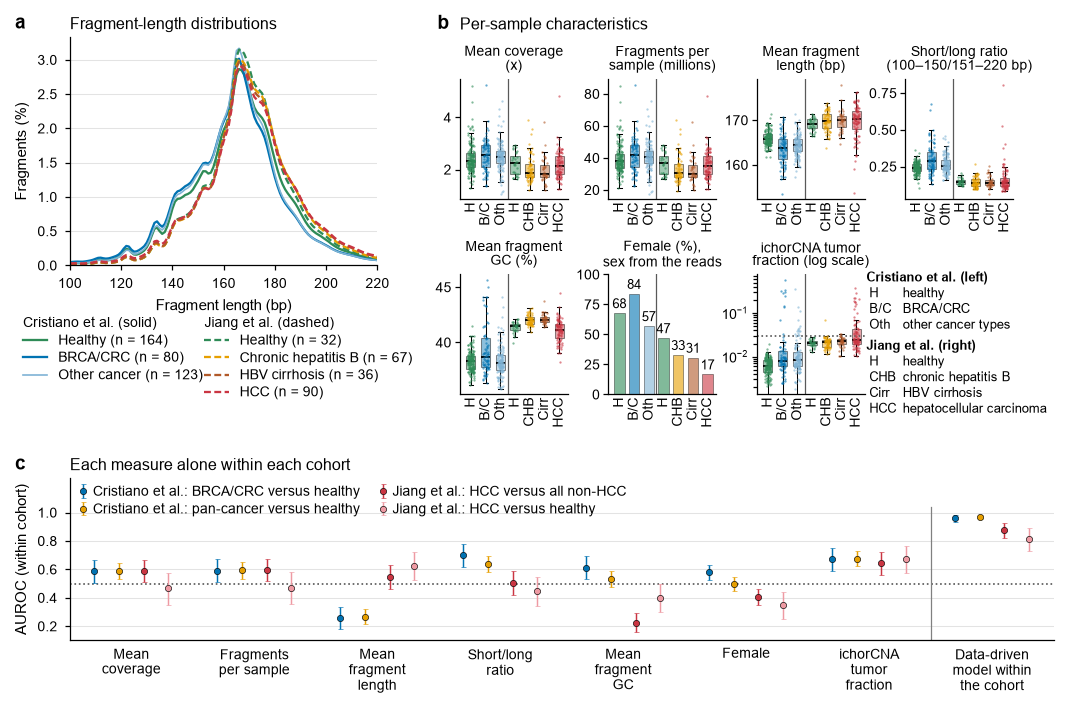

saved output\no_deep\figS_cohort_comparison_with_d.png/.pdf at 178 x 120 mm


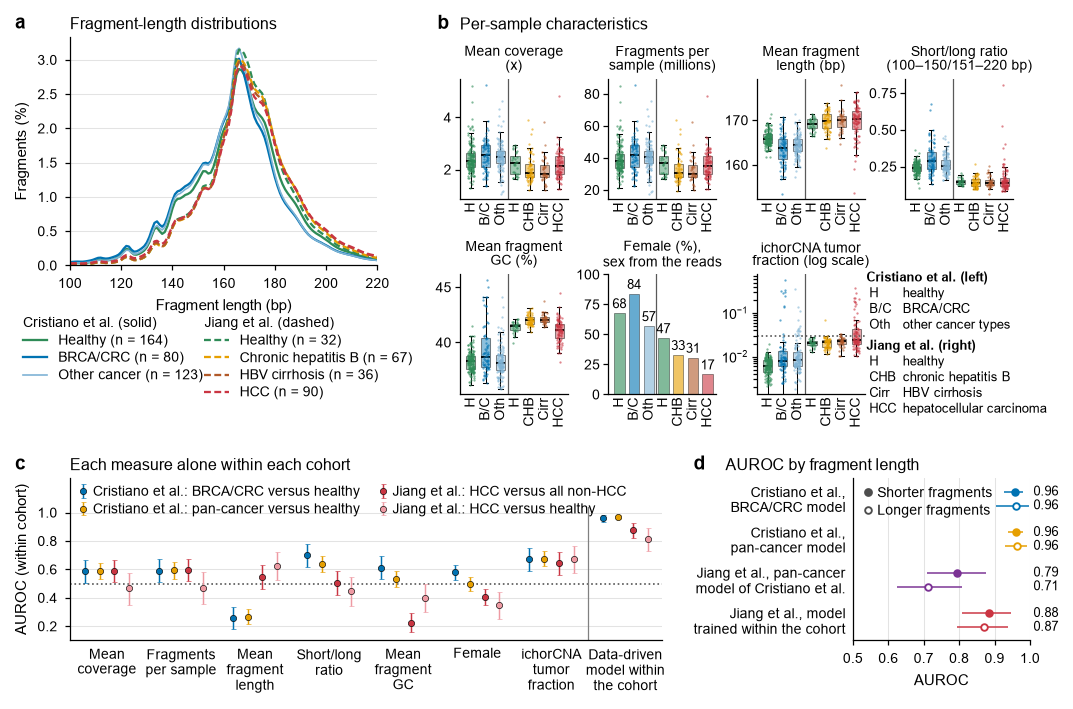

In [6]:
def assemble(with_d):
    """The figure with panels a-c, or a-d with the extra panel d.
    Shared figure style (_figstyle); a and b (seven small panels and the group key) in the
    top row, c (and d) below; every axes placed in inches from the top of the figure."""
    W, H = fs.WIDTH, 4.72
    fig = plt.figure(figsize=(W, H))

    def at(left, top, width, height):
        return fig.add_axes([left / W, (H - top - height) / H, width / W, height / H])

    # a: fragment-length distributions, the two cohort legends below
    ax_a = at(0.40, 0.24, 2.05, 1.52)
    panel_a(ax_a)
    fs.panel(ax_a, "a", "Fragment-length distributions")
    # b: seven small panels and the group key, 2 rows of 4
    x0, wb, gap = 3.0, 0.72, 0.27     # 178 mm width
    tops = [0.52, 1.82]
    axes_b = [at(x0 + (i % 4) * (wb + gap), tops[i // 4], wb, 0.80) for i in range(7)]
    panel_b(axes_b)
    fs.panel(axes_b[0], "b", "Per-sample characteristics")
    axes_b[0].set_title("Per-sample characteristics", loc="left", pad=24)     # above the measure names
    b_key(at(x0 + 3 * (wb + gap) - 0.26, tops[1] - 0.02, wb + 0.25, 1.0))
    # c (and d)
    top_c, h_c = 3.18, 1.08
    if with_d:
        ax_c = at(0.40, top_c, 3.95, h_c)
        ax_d = at(5.62, top_c, 1.18, h_c)
        panel_d(ax_d)
        fs.panel(ax_d, "d", "AUROC by fragment length")
        ax_d._left_title.set_x(-0.72)          # the title starts above the row names
    else:
        ax_c = at(0.40, top_c, W - 0.40 - 0.05, h_c)
    panel_c(ax_c)
    fs.panel(ax_c, "c", "Each measure alone within each cohort")
    return fig


# version with panels a-c and version with panel d
for with_d, stem in [(False, "figS_cohort_comparison"), (True, "figS_cohort_comparison_with_d")]:
    fig = assemble(with_d)
    fs.save(fig, out_path(stem))
    plt.show()

## Checks and numbers for the caption

In [7]:
GO = pd.MultiIndex.from_tuples(GROUP_ORDER)
print("Samples per group (panels a, b):")
print(sc.groupby(["cohort", "group"]).size().reindex(GO).to_string())
print("\nPer-group medians (panel b):")
print(sc.groupby(["cohort", "group"])[[c for c, _, _ in SCALARS] + ["ichorcna_tf"]].median().reindex(GO).round(4).to_string())
print("\nFraction female per group (panel b):")
print(sc.groupby(["cohort", "group"])["sex_female_bam"].mean().reindex(GO).round(3).to_string())
print("\nHealthy Cristiano vs healthy Jiang (cohort effect without disease):")
print(healthy_vs_healthy.round(4).to_string(index=False))
print("\nMeasures alone within each cohort, and the TSS model trained within the cohort (panel c):")
print(uni.round(3).to_string(index=False))
print("\nAUROC by fragment length (panel d; source: figS10m_fragment_length_halves.csv):")
print(fl_halves.to_string(index=False))

# panel d shows exactly the table of Fig S10 l: four rows, two halves each
assert len(fl_halves) == 8 and set(fl_halves["half"]) == {"shorter", "longer"}
assert (fl_halves.groupby("cohort")["half"].nunique() == 2).all()
assert ((fl_halves["lo"] <= fl_halves["auroc"]) & (fl_halves["auroc"] <= fl_halves["hi"])).all()
# the 225 Jiang samples and all Cristiano samples of the cohort
n_half = fl_halves.assign(n=fl_halves["n_cancer"] + fl_halves["n_control"]).groupby("cohort")["n"].sum()
print("\nsamples per row of panel d:", n_half.reindex(FL_ROWS).to_dict())
assert n_half["Jiang, model trained on Cristiano"] == 225 == n_half["Jiang, model trained within Jiang"]
assert n_half["Cristiano, PANCAN"] == (sc["cohort"] == "Cristiano").sum()
assert (sc["cohort"] == "Jiang").sum() == 225

# wording rules of the figure text
FORBIDDEN = ["PANCAN", "BRCA+CRC", "B+C", " vs ", "AUC ", "tumour", "deep-seq",
             "high-quality", "HQ"]
texts = [t.get_text() for t in fig.findobj(plt.Text) if t.get_text().strip()]
bad = [(w, t) for t in texts for w in FORBIDDEN if w in t]
assert not bad, bad
print(f"figure text: {len(texts)} text elements checked against the wording rules - ok")
assert os.path.exists(out_path("figS_cohort_comparison.png")) and os.path.exists(out_path("figS_cohort_comparison.pdf"))
print("all checks passed")

Samples per group (panels a, b):
Cristiano  Healthy                164
           BRCA+CRC                80
           Other cancer           123
Jiang      Healthy                 32
           Chronic hepatitis B     67
           HBV cirrhosis           36
           HCC                     90

Per-group medians (panel b):
                               mean_coverage  total_fragments_m  fragment_length_mean  short_long_ratio  mean_gc  ichorcna_tf
Cristiano Healthy                     2.3218            37.8087              165.7523            0.2409  38.3131       0.0062
          BRCA+CRC                    2.5693            42.0935              163.8411            0.2897  38.6750       0.0081
          Other cancer                2.4836            40.6763              164.4027            0.2510  38.1058       0.0083
Jiang     Healthy                     2.2432            36.7938              169.2238            0.1453  41.4821       0.0206
          Chronic hepatitis B         1.8